# Park access: 25 classical features and city dendrogram

1. **Cell 0** computes the 25 conventional access features (same as `feats_clustering.ipynb`) for parks, CSIMBOL `021101`, `021102`, `021104`, `021105`, and writes `city_feature_matrix_parks_25.csv`.
2. **Cell 1** ranks and standardises the features, clusters the 17 cities (Ward), picks k by silhouette and draws the dendrogram in the style of `pd_hierarchical_clustering.ipynb`.
3. **Cell 2** compares the feature clusters with the hard-coded persistent-homology parks split (superlevel H0, k = 2) and prints the mismatched cities.


**Feature subset (Cell 1).** Cell 0 computes all 25 features; Cell 1 keeps the subset in `FEATURES_KEEP` and clusters
ranked features with Ward linkage (Euclidean). Default: 20 features = 12 found by backward elimination on the silhouette
(without TDA labels) + 3 added that keep the same split + 5 more (including the
Clark-Evans ratio of parks, computed in Cell 0 alongside the 25 classical features). Use `FEATURES_KEEP = FEATURES_15` or `FEATURES_12` for the smaller sets, or `None` for all 25.

In [1]:
"""
City x feature matrix of conventional PARK-access metrics (25 classical features + Clark-Evans ratio, 17 cities).

Routing logic follows level_set_both.ipynb, with one difference: walking time
is routed to MGN *block centroids* instead of momepy tessellation cells, so that
each value links 1:1 to the DANE 2018 block table.
  - Study area: DANE urban perimeters that intersect the city's walking network.
  - Parks: CSIMBOL codes 021101, 021102, 021104, 021105, inside the study area + 1 km buffer.
  - Edge speed: slope-velocity table (5 km/h on flat edges); connectors at 5 km/h.
  - Walking time: multi-source Dijkstra; block time = network time + snap distance / 5 km/h.
  - Population weights: DANE 2018 block population; times capped at 60 min.

Usage (terminal):   python city_feature_matrix.py
Usage (notebook):   from city_feature_matrix import build_feature_matrix
                    F = build_feature_matrix()          # DataFrame, rows = cities
"""
from pathlib import Path
import time

import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.sparse import coo_matrix, csr_matrix, vstack
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree

# ----------------------------------------------------------------------------- paths / parameters
cwd = Path.cwd().resolve()
REPO = next(
    path for path in (cwd, cwd / "pedestrian_accessibility", *cwd.parents)
    if (path / "data/input/shape").is_dir()
)
SHAPE = REPO / "data/input/shape"
TABLE = REPO / "data/input/table"
RESULTS = REPO / "level_sets_blocks/results/experiment_1_complete_cities"
RESULTS.mkdir(parents=True, exist_ok=True)
OUT_CSV = RESULTS / "city_feature_matrix_parks_25.csv"

CITIES = ["barranquilla", "bogota", "bucaramanga", "cali", "cartagena", "cucuta", "ibague",
          "manizales", "medellin", "monteria", "neiva", "pasto", "pereira", "popayan",
          "santa_marta", "valledupar", "villavicencio"]

HEALTH_CODES = ["021101", "021102", "021104", "021105"]     # DANE park codes (variable name kept from the health version)


BUFFER_M = 1000                 # external buffer for health centres (m)
CONNECTOR_SPEED = 5000 / 60     # m/min (5 km/h) for block->network and centre->network connectors
T_CAP = 60.0                    # minutes; same cap as the persistence filtration
BATCH = 40                      # health centres per Dijkstra batch (memory control)
SFCA_CATCH = 15.0               # minutes; catchment for the two-step floating catchment area (2SFCA)

FEATURES = {
    # supply
    "hosp_per100k":          "Health centres per 100k residents",
    "hosp_per_km2":          "Health centres per km² of study area",
    # walking-time distribution (population-weighted)
    "t_p25":                 "25th percentile walking time (min)",
    "t_p50":                 "Median walking time (min)",
    "t_p90":                 "90th percentile walking time (min)",
    "share_lt10":            "Share of residents < 10 min from a centre",
    "share_lt5":             "Share of residents < 5 min from a centre",
    "t_iqr":                 "Interquartile range of walking time, p75 - p25 (min)",
    "share_gt30":            "Share of residents > 30 min from a centre (coverage gap)",
    # redundancy / choice
    "share_ge3_hc15":        "Share of residents with >= 3 centres within 15 min",
    "n_hc15_pw":             "Mean number of centres reachable within 15 min (per resident)",
    "n_hc30_pw":             "Mean number of centres reachable within 30 min (per resident)",
    "share_no_hc15":         "Share of residents with no centre within 15 min",
    "share_ge2_hc15":        "Share of residents with >= 2 centres within 15 min (backup coverage)",
    "backup_penalty_p50":    "Median extra walking time if the nearest centre closed (2nd - 1st, min)",
    "t2_p50":                "Median walking time to the 2nd-nearest centre (min)",
    # catchments
    "catchment_load_pw_p50": "Median population sharing a resident's nearest centre",
    "catchment_pop_cv":      "Coefficient of variation of catchment population across centres",
    "sfca15_p50":            "2SFCA accessibility, 15-min catchment: median centres per 10k residents",
    "area_cov15":            "Share of inhabited block area within 15 min of a centre (spatial coverage)",
    # geometry / network
    "euclid_p50_m":          "Median straight-line distance to the nearest centre (m)",
    "share_beyond_800m_euclid": "Share of residents > 800 m straight-line from a centre",
    "share_net_grade_gt10":  "Share of network length with grade > 10%",
    # inequality / equity
    "gini_time":             "Gini coefficient of walking time (population-weighted)",
    "gap_bajo_alto":         "Mean walking time, low strata (1-2) minus high strata (5-6) (min)",
    "clark_evans_R":         "Clark-Evans nearest-neighbour ratio of parks (< 1 clustered, 1 random, > 1 dispersed)",
}


# ----------------------------------------------------------------------------- helpers
def wquantile(x, w, q):
    """Weighted quantile (linear interpolation on the cumulative weight)."""
    o = np.argsort(x)
    x, w = x[o], w[o]
    c = np.cumsum(w) / w.sum()
    return float(np.interp(q, c, x))


def wgini(x, w):
    """Population-weighted Gini coefficient."""
    o = np.argsort(x)
    x, w = x[o], w[o]
    p = np.concatenate([[0], np.cumsum(w) / w.sum()])
    L = np.concatenate([[0], np.cumsum(w * x) / (w * x).sum()])
    return float(1 - np.sum((p[1:] - p[:-1]) * (L[1:] + L[:-1])))


def edge_speeds(edges, speed_table):
    """Slope-dependent walking speed (km/h) per edge, as in the notebook."""
    sp = np.zeros(len(edges))
    g = edges["grade_abs"].to_numpy()
    for iv in speed_table.itertuples(index=False):
        sp[(g > iv.s1) & (g <= iv.s2)] = iv.speed
    sp[g == 0] = 5.0
    sp[g > speed_table["s2"].max()] = speed_table.iloc[0]["speed"]
    return sp


# ----------------------------------------------------------------------------- shared inputs (read once)
def load_shared():
    speed_table = pd.read_csv(TABLE / "slope_velocity_data.csv", sep=";")
    speed_table.columns = [c.strip("\ufeff") for c in speed_table.columns]
    perims = gpd.read_file(SHAPE / "Colombia_urban_perimeters_name_pop/Colombia_urban_perimeters_name_pop.shp")
    dane = pd.read_csv(TABLE / "DANE_2018_personas_manz.txt",
                       usecols=["MANZ_CCNCT", "poblacion", "estrato_bajo", "estrato_alto"],
                       dtype={"MANZ_CCNCT": "string"}, low_memory=False)
    return speed_table, perims, dane


# ----------------------------------------------------------------------------- per-city computation
def city_features(city, speed_table, perims_all, dane):
    t0 = time.time()

    # --- network
    edge_path = next((SHAPE / "edges").glob(f"{city}-*_edges.shp"))
    nid = edge_path.stem.removesuffix("_edges").rsplit("-", 1)[1]
    raw_nodes = gpd.read_file(SHAPE / "nodes" / f"{city}-{nid}_nodes.shp")
    crs = raw_nodes.to_crs("EPSG:4326").estimate_utm_crs()
    edges = gpd.read_file(edge_path).to_crs(crs)
    nodes = raw_nodes.to_crs(crs)
    edges["from"] = edges["from"].astype(str)
    edges["to"] = edges["to"].astype(str)
    nodes["osmid"] = nodes["osmid"].astype(str)
    edges["w"] = edges["length"] / (edge_speeds(edges, speed_table) * 1000 / 60)   # minutes

    # --- study area = urban perimeters touched by the network
    perims = perims_all.to_crs(crs)
    hits = gpd.sjoin(edges[["geometry"]], perims[["ID_mpio", "geometry"]], predicate="intersects")
    city_geom = perims[perims["ID_mpio"].isin(hits["ID_mpio"].unique())].geometry.union_all()
    area_km2 = city_geom.area / 1e6

    # --- blocks + DANE attributes
    poly = gpd.GeoDataFrame({"geometry": [city_geom]}, crs=crs)
    cand = gpd.read_file(SHAPE / "MANZANA/MGN_URB_MANZANA.shp",
                         mask=poly.to_crs("EPSG:4326").geometry.iloc[0]).to_crs(crs)
    blocks = (gpd.sjoin(cand, poly, predicate="intersects").drop(columns="index_right")
              .drop_duplicates("MANZ_CCNCT").reset_index(drop=True))
    blocks["MANZ_CCNCT"] = blocks["MANZ_CCNCT"].astype("string")
    blocks = blocks.merge(dane, on="MANZ_CCNCT", how="left", validate="one_to_one")

    # --- health centres in study area + buffer
    buf = city_geom.buffer(BUFFER_M)
    eq = gpd.read_file(SHAPE / "colombia_equipments_ID/colombia_equipments_ID.shp",
                       mask=gpd.GeoSeries([buf], crs=crs).to_crs("EPSG:4326").iloc[0]).to_crs(crs)
    eq["CSIMBOL"] = eq["CSIMBOL"].astype("string").str.strip()
    hc = eq[eq["CSIMBOL"].isin(HEALTH_CODES) & eq.geometry.intersects(buf)].reset_index(drop=True)
    H = len(hc)
    hxy = np.column_stack([hc.geometry.x, hc.geometry.y])

    # --- graph: undirected, parallel edges -> minimum time, no self-loops
    ids = pd.Index(pd.unique(np.concatenate([edges["from"].to_numpy(), edges["to"].to_numpy()])))
    u, v = ids.get_indexer(edges["from"]), ids.get_indexer(edges["to"])
    e = pd.DataFrame({"a": np.minimum(u, v), "b": np.maximum(u, v), "w": edges["w"].to_numpy()})
    e = e[e.a != e.b].groupby(["a", "b"], as_index=False)["w"].min()
    N = len(ids)

    nn = nodes.drop_duplicates("osmid").set_index("osmid").reindex(ids)
    have = nn.geometry.notna().to_numpy()
    nxy = np.column_stack([nn.geometry.x.to_numpy(), nn.geometry.y.to_numpy()])
    tree_idx = np.flatnonzero(have)
    tree = cKDTree(nxy[have])

    # one virtual source node per centre (keeps the connector cost and the centre identity)
    hd, hp = tree.query(hxy)
    hnode = tree_idx[hp]
    hcon = np.maximum(hd / CONNECTOR_SPEED, 1e-9)          # csgraph treats 0 as "no edge"
    rows = np.concatenate([e.a, e.b, N + np.arange(H)])
    cols = np.concatenate([e.b, e.a, hnode])
    vals = np.concatenate([e.w, e.w, hcon])
    G = coo_matrix((vals, (rows, cols)), shape=(N + H, N + H)).tocsr()

    # nearest centre: time + which centre
    dist, _, src = dijkstra(G, directed=True, indices=N + np.arange(H),
                            min_only=True, return_predecessors=True)
    # --- attach blocks to the network (centroid -> nearest network node)
    cen = blocks.geometry.centroid
    bxy = np.column_stack([cen.x, cen.y])
    bd, bp = tree.query(bxy)
    bn = tree_idx[bp]
    snap_t = bd / CONNECTOR_SPEED
    pop_all = blocks["poblacion"].fillna(0).to_numpy(float)

    # counts within 15/30 min, 2nd-nearest time and the centre->block 15-min reach matrix
    # (batched, truncated at T_CAP)
    reach_rows = []
    n15 = np.zeros(N, np.int32)
    n30 = np.zeros(N, np.int32)
    best = np.full(N, np.inf)
    second = np.full(N, np.inf)
    for i0 in range(0, H, BATCH):
        D = dijkstra(G, directed=True, indices=N + np.arange(i0, min(H, i0 + BATCH)), limit=T_CAP)[:, :N]
        n15 += (D <= 15).sum(0)
        n30 += (D <= 30).sum(0)
        stack = np.vstack([best, second, D])
        stack.sort(axis=0)
        best, second = stack[0], stack[1]
        reach_rows.append(csr_matrix((D[:, bn] + snap_t[None, :]) <= SFCA_CATCH))   # centres x blocks

    # --- 2SFCA (Luo & Wang 2003), binary 15-min catchment, every centre has capacity 1
    reach = vstack(reach_rows).tocsr().astype(float)       # H x n_blocks
    demand = reach @ pop_all                                # residents within 15 min of each centre
    ratio = np.divide(1.0, demand, out=np.zeros(H), where=demand > 0)
    sfca = (reach.T @ ratio) * 1e4                          # centres per 10k residents, per block

    t_raw = dist[bn] + snap_t
    reached = np.isfinite(t_raw)

    t = np.minimum(t_raw, T_CAP)[reached]
    t2 = np.minimum(second[bn] + snap_t, T_CAP)[reached]
    hc_id = (src[bn] - N)[reached]
    k15 = n15[bn][reached]
    k30 = n30[bn][reached]
    d_euc = cKDTree(hxy).query(bxy)[0][reached]
    pop = pop_all[reached]
    sfca_r = sfca[reached]
    barea = blocks.geometry.area.to_numpy()[reached]
    low = blocks["estrato_bajo"].fillna(0).to_numpy(float)[reached]
    high = blocks["estrato_alto"].fillna(0).to_numpy(float)[reached]

    m = pop > 0                                   # inhabited, reachable blocks
    tp, pp = t[m], pop[m]
    total_pop = pop.sum()                         # population of reachable blocks

    # catchments: population whose nearest centre is each centre (zeros kept)
    load = np.bincount(hc_id[m], weights=pp, minlength=H)

    # equity: strata-weighted mean times (block strata columns are population shares)
    wl, wh = pp * low[m], pp * high[m]
    t_low = np.average(tp, weights=wl) if wl.sum() > 0 else np.nan
    t_high = np.average(tp, weights=wh) if wh.sum() > 0 else np.nan

    # terrain (grade_abs is a fraction: 0.10 = 10 %)
    L = edges["length"].to_numpy(float)
    gr = edges["grade_abs"].to_numpy(float)

    # park spatial pattern: Clark-Evans ratio (parks inside the study area only)
    cin = hc.geometry.within(city_geom).to_numpy()
    nin = int(cin.sum())
    if nin >= 2:
        nn_d = cKDTree(hxy[cin]).query(hxy[cin], k=2)[0][:, 1]
        ce_R = nn_d.mean() / (0.5 * np.sqrt(city_geom.area / nin))
    else:
        ce_R = np.nan

    f = {
        "hosp_per100k":          H / total_pop * 1e5,
        "hosp_per_km2":          H / area_km2,
        "t_p25":                 wquantile(tp, pp, 0.25),
        "t_p50":                 wquantile(tp, pp, 0.50),
        "t_p90":                 wquantile(tp, pp, 0.90),
        "share_lt10":            pp[tp < 10].sum() / pp.sum(),
        "share_lt5":             pp[tp < 5].sum() / pp.sum(),
        "t_iqr":                 wquantile(tp, pp, 0.75) - wquantile(tp, pp, 0.25),
        "share_gt30":            pp[tp > 30].sum() / pp.sum(),
        "share_ge3_hc15":        pp[k15[m] >= 3].sum() / pp.sum(),
        "n_hc15_pw":             np.average(k15[m], weights=pp),
        "n_hc30_pw":             np.average(k30[m], weights=pp),
        "share_no_hc15":         pp[k15[m] == 0].sum() / pp.sum(),
        "share_ge2_hc15":        pp[k15[m] >= 2].sum() / pp.sum(),
        "backup_penalty_p50":    wquantile(t2[m] - tp, pp, 0.50),
        "t2_p50":                wquantile(t2[m], pp, 0.50),
        "catchment_load_pw_p50": wquantile(load[hc_id[m]], pp, 0.50),
        "catchment_pop_cv":      load.std() / load.mean(),
        "sfca15_p50":            wquantile(sfca_r[m], pp, 0.50),
        "area_cov15":            barea[m][tp <= 15].sum() / barea[m].sum(),
        "euclid_p50_m":          wquantile(d_euc[m], pp, 0.50),
        "share_beyond_800m_euclid": pp[d_euc[m] > 800].sum() / pp.sum(),
        "share_net_grade_gt10":  L[gr > 0.10].sum() / L.sum(),
        "gini_time":             wgini(tp, pp),
        "gap_bajo_alto":         t_low - t_high,
        "clark_evans_R":         ce_R,
    }
    print(f"{city:<14} blocks={len(blocks):>6}  centres={H:>4}  unreached={int((~reached).sum()):>4}  "
          f"{time.time() - t0:5.1f}s", flush=True)
    return f


# ----------------------------------------------------------------------------- driver
def build_feature_matrix(cities=CITIES, out_csv=OUT_CSV):
    speed_table, perims_all, dane = load_shared()
    F = pd.DataFrame({c: city_features(c, speed_table, perims_all, dane) for c in cities}).T
    F.index.name = "city"
    F = F[list(FEATURES)]
    if out_csv is not None:
        F.to_csv(out_csv)
        pd.Series(FEATURES, name="description").rename_axis("feature").to_csv(
            Path(out_csv).with_name("city_feature_dictionary_parks_25.csv"))
    return F


if __name__ == "__main__":
    F = build_feature_matrix()
    pd.set_option("display.width", 200)
    print(F.round(3))
    # Standardised version (z-scores per feature), e.g. for clustering / PCA:
    Z = (F - F.mean()) / F.std(ddof=0)
    Z.to_csv(OUT_CSV.with_name("city_feature_matrix_parks_25_zscores.csv"))

barranquilla   blocks= 16919  centres= 126  unreached=  72    3.9s
bogota         blocks= 49343  centres=1339  unreached=  77   25.8s
bucaramanga    blocks=  9479  centres= 190  unreached=  56    2.6s
cali           blocks= 16198  centres= 174  unreached=  25    4.0s
cartagena      blocks=  9759  centres= 189  unreached=  29    3.3s
cucuta         blocks= 10858  centres= 164  unreached=  63    2.2s
ibague         blocks=  5576  centres= 168  unreached=  20    2.5s
manizales      blocks=  4254  centres=  50  unreached=  21    2.1s
medellin       blocks= 20224  centres= 468  unreached=  51   11.0s
monteria       blocks=  5074  centres= 159  unreached=  30    0.8s
neiva          blocks=  5208  centres=  69  unreached=   0    0.9s
pasto          blocks=  3300  centres=  65  unreached=  24    1.0s
pereira        blocks=  6288  centres= 170  unreached=   4    1.9s
popayan        blocks=  3420  centres=  45  unreached=  13    1.1s
santa_marta    blocks=  5300  centres=  80  unreached=  19    

15 features, transform = rank, linkage = ward, metric = euclidean, cophenetic r = 0.709
Euclidean silhouette at k = 2: 0.438
silhouette by k: {2: 0.438, 3: 0.371, 4: 0.288, 5: 0.252, 6: 0.238, 7: 0.232, 8: 0.217}
cluster 1: Bogota, Ibague, Monteria, Neiva, Pasto, Pereira, Villavicencio
cluster 2: Barranquilla, Bucaramanga, Cali, Cartagena, Cucuta, Manizales, Medellin, Popayan, Santa Marta, Valledupar


/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/anaconda3/envs/kernels

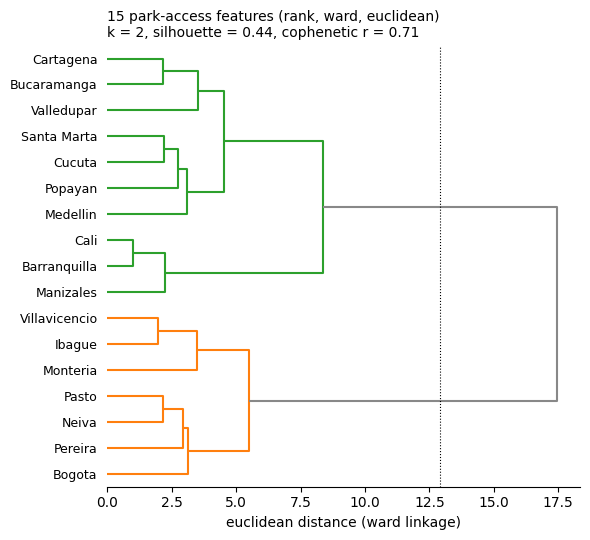

In [2]:
# =============================================================================
# CELL 1 — Hierarchical clustering of the 17 cities on the park features
# Each feature is ranked across cities (TRANSFORM = "rank") so that no single extreme
# city (e.g. Montería, Villavicencio) dominates the distances; ranks are then
# standardised so all features weigh the same. The TDA classes are NOT used here.
# =============================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet, set_link_color_palette
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score

FEATURE_CSV = OUT_CSV                      # written by Cell 0
TRANSFORM = "rank"                         # "rank" (outlier-robust) or "z" (plain z-scores)
LINKAGE = "ward"                           # "ward" (Euclidean only), "average", "complete"
METRIC = "euclidean"                       # "euclidean", "cityblock" (ignored by ward)
# 12 features found by backward elimination on the Euclidean-Ward silhouette (no TDA labels used)
FEATURES_12 = ["hosp_per100k", "hosp_per_km2", "t_p25", "t_p50", "share_lt10", "share_lt5", "share_ge3_hc15", "share_ge2_hc15", "t2_p50", "sfca15_p50", "euclid_p50_m", "share_beyond_800m_euclid"]
# 3 features added to reach 15: of all 286 sets of 3 from the remaining 13, the one with the highest
# silhouette among those that keep the 12-feature split and bootstrap stability >= 0.9
FEATURES_ADD3 = ["n_hc15_pw", "share_no_hc15", "area_cov15"]
FEATURES_15 = FEATURES_12 + FEATURES_ADD3
# 5 features added to reach 20. Searched over swaps of the remaining classical features + the Clark-Evans ratio
# (slope and code-specific features excluded); highest silhouette with 2 mismatched cities and stability >= 0.9.
FEATURES_ADD5 = ["t_p90", "t_iqr", "n_hc30_pw", "catchment_load_pw_p50", "clark_evans_R"]
# Previous choice (silhouette 0.363, only Cartagena mismatched):
# FEATURES_ADD5 = ["t_p90", "t_iqr", "share_gt30", "n_hc30_pw", "backup_penalty_p50"]
FEATURES_KEEP = FEATURES_15 + FEATURES_ADD5      # 20 features; FEATURES_15 or FEATURES_12 for smaller sets, None for all 25
K_RANGE = range(2, 9)
K = 2                                      # same k as the TDA split; None = best k by silhouette
OUT_DIR = FEATURE_CSV.parent / "feature_clustering_parks_best"
OUT_DIR.mkdir(exist_ok=True)

F = pd.read_csv(FEATURE_CSV, index_col="city")
assert F.notna().all().all(), F.columns[F.isna().any()].tolist()
if FEATURES_KEEP:
    missing = [f for f in FEATURES_KEEP if f not in F.columns]
    assert not missing, f"not in the feature matrix (re-run Cell 0 with them): {missing}"
    F = F[FEATURES_KEEP]
if LINKAGE == "ward":
    METRIC = "euclidean"
cities = F.index.tolist()
X0 = F.rank() if TRANSFORM == "rank" else F
X = ((X0 - X0.mean()) / X0.std(ddof=0)).to_numpy()

D = pdist(X, METRIC)
Z = linkage(X, method="ward") if LINKAGE == "ward" else linkage(D, method=LINKAGE)
coph = cophenet(Z, D)[0]
sil_k = {k: silhouette_score(X, fcluster(Z, k, "maxclust"), metric=METRIC) for k in K_RANGE}
sil_euc = silhouette_score(X, fcluster(Z, K or 2, "maxclust"))   # Euclidean silhouette, for comparison
k_best = K or max(sil_k, key=sil_k.get)
labels = fcluster(Z, k_best, "maxclust")
FEAT_CLUSTERS = pd.Series(labels, index=cities, name="feature_cluster")
FEAT_CLUSTERS.to_csv(OUT_DIR / f"clusters_{F.shape[1]}f_{TRANSFORM}_{LINKAGE}_{METRIC}_k{k_best}.csv")

print(f"{F.shape[1]} features, transform = {TRANSFORM}, linkage = {LINKAGE}, metric = {METRIC}, cophenetic r = {coph:.3f}")
print(f"Euclidean silhouette at k = {K or 2}: {sil_euc:.3f}")
print("silhouette by k:", {k: round(v, 3) for k, v in sil_k.items()})
for c in sorted(set(labels)):
    print(f"cluster {c}:", ", ".join(x.replace("_", " ").title() for x in FEAT_CLUSTERS.index[labels == c]))

# ---- dendrogram, same style as pd_hierarchical_clustering.ipynb -------------------
thr = 0.5 * (Z[-(k_best - 1), 2] + Z[-k_best, 2])        # cut midway between merges -> k_best clusters
fig, ax = plt.subplots(figsize=(6, 5.5))
# Cluster colours follow drawing order (bottom cluster first). The order is swapped from scipy's
# default ("C1" orange, "C2" green) so the colours match the TDA dendrogram. Set to None for the default.
CLUSTER_PALETTE = ["C2", "C1"]
if CLUSTER_PALETTE is not None:
    set_link_color_palette(CLUSTER_PALETTE)
dendrogram(Z, labels=[c.replace("_", " ").title() for c in cities], orientation="right",
           ax=ax, color_threshold=thr, above_threshold_color="#888888", leaf_font_size=9)
set_link_color_palette(None)                                 # restore scipy's default palette
ax.axvline(thr, color="k", ls=":", lw=0.8)
ax.set_title(f"{F.shape[1]} park-access features ({TRANSFORM}, {LINKAGE}, {METRIC})\n"
             f"{'best k' if K is None else 'k'} = {k_best}, silhouette = {sil_k[k_best]:.2f}, cophenetic r = {coph:.2f}",
             fontsize=10, loc="left")
ax.set_xlabel(f"{METRIC} distance ({LINKAGE} linkage)")
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / f"dendrogram_{F.shape[1]}f_{TRANSFORM}_{LINKAGE}_{METRIC}_k{k_best}.png", dpi=200, bbox_inches="tight")
plt.show()


In [3]:
# =============================================================================
# CELL 2 — Compare with the persistent-homology parks split (hard-coded)
# Superlevel H0, normalized OT, best k = 2 (dendrogram of the TDA notebook).
# =============================================================================
from sklearn.metrics import adjusted_rand_score

TDA_SPLIT = {
    "green":  ["ibague", "cartagena", "monteria", "pasto", "neiva", "pereira",
               "bogota", "valledupar", "villavicencio"],
    "orange": ["santa_marta", "manizales", "popayan", "bucaramanga", "cucuta",
               "cali", "barranquilla", "medellin"],
}
tda = pd.Series({c: g for g, cs in TDA_SPLIT.items() for c in cs}, name="tda")
assert set(tda.index) == set(cities), set(tda.index) ^ set(cities)
tda = tda.reindex(cities)

cmp_ = pd.concat([FEAT_CLUSTERS, tda], axis=1)
print("Contingency table (rows = feature clusters, columns = TDA classes):")
display(pd.crosstab(cmp_.feature_cluster, cmp_.tda))
print(f"ARI (feature clusters vs TDA split) = {adjusted_rand_score(cmp_.tda, cmp_.feature_cluster):.3f}")

# each feature cluster is assigned the TDA class held by most of its cities;
# a city is mismatched if its own TDA class differs from that majority
majority = cmp_.groupby("feature_cluster").tda.agg(lambda s: s.value_counts().idxmax())
cmp_["cluster_majority"] = cmp_.feature_cluster.map(majority)
cmp_["mismatched"] = cmp_.tda != cmp_.cluster_majority
print("\nMajority TDA class of each feature cluster:", majority.to_dict())
mis = cmp_[cmp_.mismatched]
print(f"Mismatched cities ({len(mis)} of {len(cmp_)}):")
for c, r in mis.iterrows():
    print(f"  {c.replace('_', ' ').title():<14} TDA = {r.tda:<6}  in feature cluster {r.feature_cluster} (majority {r.cluster_majority})")
cmp_.to_csv(OUT_DIR / f"tda_comparison_{F.shape[1]}f_{TRANSFORM}_{LINKAGE}_{METRIC}_k{k_best}.csv")


Contingency table (rows = feature clusters, columns = TDA classes):


tda,green,orange
feature_cluster,,
1,7,0
2,2,8


ARI (feature clusters vs TDA split) = 0.558

Majority TDA class of each feature cluster: {1: 'green', 2: 'orange'}
Mismatched cities (2 of 17):
  Cartagena      TDA = green   in feature cluster 2 (majority orange)
  Valledupar     TDA = green   in feature cluster 2 (majority orange)
